# **Initialization**

In [83]:
# Essential Libraries
import os
from os import path
import glob
from pathlib import Path

# Data Handling
import numpy as np
import pandas as pd
import xarray as xr
import scipy as sp

# Data Visualization
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

# Statistics
from statistics import mean, stdev

# Microscopy File Handling
import tifffile
from tifffile import TiffWriter
import nd2

# Miscellaneous
import tqdm

# GUI
import ipywidgets as widgets
from IPython.display import display

In [4]:
global_filepath_input = widgets.Text(placeholder = 'Enter File Path Here', description = 'File Path:')
display(global_filepath_input)

Text(value='', description='File Path:', placeholder='Enter File Path Here')

In [5]:
global_filepath = Path(str(global_filepath_input.value))

# **Utilities**

In [ ]:
def generate_output_filepath(parent = global_filepath, file_string = None, subfolder=None):
    """
    Generates output filepath and subfolder (if applicable) to save files.

    Parameters: 
    -   parent: pathlib.Path
            Parent filepath used to save folder. Often is the main filepath that is used to open files (global_filepath).

    -   file_string: str or pathlib.Path
            Stem of file name. Must contain file extension.

    -   subfolder: str or pathlib.Path
            Subdirectory used to save file separately from parent. Convenient if the parent directory is global_filepath 
            and a subdirectory will be used to store data from a specific run or a specific type of processed data.

    Returns: 
    -   output_filepath: pathlib.Path
            Path object that can be used to save files (e.g. in pd.to_csv() function)
    """


    # Checks whether file_string was added
    if not file_string: 
        raise ValueError('Must include filename stem and extension')
    
    # Converts file_string to Path object if required
    if not isinstance(file_string, Path):
        file_string = Path(file_string)

    # Checks that file_string has extension
    if not file_string.suffix:
        raise ValueError('File path must include extension')
    
    # Adds subfolder to output path if specified
    if subfolder:
        subfolder_path = parent / Path(subfolder)

        # Ensures that subfolder exists
        if not subfolder_path.exists():
            subfolder_path.mkdir(parents = True, exist_ok = True)

        # Generates output filepath in output subfolder
        output_filepath = subfolder_path / file_string

    else:
        # Generates output filepath in parent folder
        output_filepath = parent / file_string
    
    return output_filepath

# **Image Analysis Functions**

In [ ]:
# Lists details of image files (e.g. metadata, number of channels, etc) in specified folder

files = global_filepath.glob('*.nd2')

for file in files: 
    with nd2.ND2File(file) as f: 
        print(f.shape)
        print(f.metadata)

(30, 10, 2, 1608, 1608)
Metadata(contents=Contents(channelCount=2, frameCount=300), channels=[Channel(channel=ChannelMeta(name='New', index=0, color=Color(r=43, g=255, b=25, a=1.0), emissionLambdaNm=522.5, excitationLambdaNm=470.0), loops=LoopIndices(NETimeLoop=0, TimeLoop=None, XYPosLoop=1, ZStackLoop=None), microscope=Microscope(objectiveMagnification=100.0, objectiveName='Apo TIRF 100x Oil DIC N2', objectiveNumericalAperture=1.49, zoomMagnification=1.0, immersionRefractiveIndex=1.515, projectiveMagnification=None, pinholeDiameterUm=None, modalityFlags=['fluorescence', 'camera']), volume=Volume(axesCalibrated=(True, True, False), axesCalibration=(0.11, 0.11, 1.0), axesInterpretation=('distance', 'distance', 'distance'), bitsPerComponentInMemory=16, bitsPerComponentSignificant=16, cameraTransformationMatrix=(-0.9999873620819255, -0.0050274920618496215, 0.0050274920618496215, -0.9999873620819255), componentCount=1, componentDataType='unsigned', voxelCount=(1608, 1608, 1), componentMaxi

Image Brightness Functions

In [ ]:
def image_brightness(filepath, px_vert = 500, px_hor = 500):
    """
    Calculates the mean brightness of the center square of an single- or multi-channel image containing one ROI. Image may contain more than one frame in t dimension.

    Parameters: 
    -   filepath: pathlib.Path or str
            Points function to target file.

    -   px_vert: int
            Determines the vertical size of the bounding box (in pixels) used for intensity calculation. 

    -   px_hor: int
            Determines the horizontal size of the bounding box (in pixels) used for intensity calculation. 

    Returns: 
    -   ndarray of channel labels, mean intensities, and standard deviations of intensity
    """

    # Calculates bounding box edge distance from center for each dimension
    v = px_vert // 2
    h = px_hor // 2

    output_arr = []

    # Opens file using context manager
    with nd2.ND2File(filepath) as f: 
        array = f.to_xarray()

        # Extract metadata from file
        md = f.metadata
        ch_count = md.contents.channelCount
        frame_count = md.contents.frameCount

        # Cycle through frames if applicable
        if frame_count != 1:
            for i in range(frame_count):
                frame_arr = array[i]

                # Extract gray values from each channel
                for label, slice in frame_arr.groupby('C'):

                    # Determine center point of ROI
                    mid_x = len(slice.coords['X']) // 2
                    mid_y = len(slice.coords['Y']) // 2

                    # Collect gray values into array and only retain values within bounding box defined by px_vert and px_hor
                    intensities = np.array(slice.values)[0]
                    roi_intensities = intensities[mid_x - h : mid_x + h, mid_y - v : mid_y + v]

                    # Appends mean and SD to output_arr
                    mean_intensity = np.mean(roi_intensities)
                    sd_intensity = np.std(roi_intensities)
                    output_arr.append([label, mean_intensity, sd_intensity])
        else: 
            frame_arr = array
            for label, slice in frame_arr.groupby('C'):
                
                mid_x = len(slice.coords['X']) // 2

                mid_y = len(slice.coords['Y']) // 2

                intensities = np.array(slice.values)[0]
                roi_intensities = intensities[mid_x - h : mid_x + h, mid_y - v : mid_y + v]

                mean_intensity = np.mean(roi_intensities)
                sd_intensity = np.std(roi_intensities)
                output_arr.append([label, mean_intensity, sd_intensity])

    return np.asarray(output_arr)
        

In [ ]:
def image_brightness_table(main_folder, px_vert = 500, px_hor = 500, save_file = True, file_name = 'Intensities.csv', file_path = global_filepath, exclude_brightfield = True):
    """
    Creates and saves a table of image brightnesses by calling image_brightness function. Intended for a folder including .nd2 files generated from surface inspections and time-lapses.

    Parameters: 
    -   main_folder: pathlib.Path
            Points to folder containing .nd2 files.

    -   px_vert: int
            Defines vertical size of bounding box (in pixels) used to calculate the intensity of the surface. Passed to image_brightness function.

    -   px_hor: int
            Defines horizontal size of bounding box (in pixels) used to calculate the intensity of the surface. Passed to image_brightness function.

    -   save_file: bool 
            Saves output file if True. 

    -   file_name: str
            Name of saved csv file (if applicable). Not called if save_file is False.

    -   file_path: pathlib.Path
            Destination folder for saved csv file (if applicable). Not called if save_file is False.

    -   exclude_brightfield: bool 
            Drops results for brightfield channel if True. 

    Dependencies: 
    -   generate_output_filepath
    
    -   image_brightness

    Returns: 
    -   output_df: DataFrame
            Contains image intensity information
    
    """
    # main_folder must be Path object
    
    image_files = main_folder.glob('*.nd2')

    output = []

    # Cycles through image files
    for file in tqdm.tqdm(image_files, desc = 'Calculating Image Intensities'): 

        # Ignores files larger than 1GB (Used to differentiate between still images and time-lapses. Optional.)
        size = file.stat().st_size
        if size > 1e9: continue


        arr = image_brightness(file, px_vert = px_vert, px_hor = px_hor)
        num_channels = len(arr)
        file_arr = np.full(num_channels, file.stem)
        arr = np.column_stack([file_arr, arr])
        output.append(np.array(arr))
        
    output = np.vstack(output)

    if exclude_brightfield:
        mask = ['Bright' not in val for val in output[:,1]]
        output = np.vstack(output[mask])

    output_df = pd.DataFrame(output, columns=['File', 'Channel', 'Mean Intensity', 'SD Intensity'])

    if save_file: 
        output_path = generate_output_filepath(file_string = file_name, parent = file_path)
        output_df.to_csv(output_path, index = False)
        
    return output_df

# **Calculate Image Intensities**

In [15]:
intensities_df = image_brightness_table(main_folder = global_filepath, file_name = '20260618_Pre-Digestion_Suitability_ExoIII-Buff_JH-ELN-0002-0015.csv')

Calculating Image Intensities: 0it [00:00, ?it/s]c:\Users\joshu\anaconda3\envs\hs-analysis\Lib\site-packages\numpy\core\fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\joshu\anaconda3\envs\hs-analysis\Lib\site-packages\numpy\core\_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
c:\Users\joshu\anaconda3\envs\hs-analysis\Lib\site-packages\numpy\core\_methods.py:206: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
c:\Users\joshu\anaconda3\envs\hs-analysis\Lib\site-packages\numpy\core\_methods.py:163: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
c:\Users\joshu\anaconda3\envs\hs-analysis\Lib\site-packages\numpy\core\_methods.py:198: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
Calculating

IndexError: Index 30 is out of bounds for axis 0 with size 30

In [54]:
calibration_filepath = Path(r'F:\Data\20260618 - ExoIII Surface Density Test_JH-ELN-0002-0015\Calibration')
unknowns_filepath = Path(r'F:\Data\20260618 - ExoIII Surface Density Test_JH-ELN-0002-0015\Post-Digestion')


intensities_calibration = image_brightness_table(main_folder = calibration_filepath, save_file=False)
intensities_unknowns = image_brightness_table(main_folder = unknowns_filepath, save_file=False)

Calculating Image Intensities: 6it [00:02,  2.91it/s]
Calculating Image Intensities: 6it [00:02,  2.95it/s]


In [ ]:
image_files = global_filepath.glob('*.nd2')

# **Calculate Non-Specific Degradation vs. Photobleaching**

In [42]:
selected_ROIs = {
    'W2' : [1, 2, 6, 9, 10],
    'W3' : [1, 5, 7, 9, 10],
    'W4' : [1, 4, 7, 9, 10],
    'W5' : [1, 4, 7, 9, 10]
}

retained_P = {}

for k, v in selected_ROIs.items():
    for i in range(len(v)): v[i] -= 1
    retained_P[k] = [f'XYPos:{x}' for x in v]


files = global_filepath.glob('*.nd2')

x_shape = 500
y_shape = 500

for file in files: 
    output_filename = f'{file.stem}_Retained_Means.csv'
    output_filepath = generate_output_filepath(parent = global_filepath, subfolder = 'Retained ROIs', file_string = output_filename)

    for k, v in retained_P.items(): 
        if k in file.stem:
            well_id = k
            sel_ROIs = v 
    print(sel_ROIs)

    with nd2.ND2File(file) as f: 
        retained_channels = [x for x in f._channel_names if 'Bright' not in x]
        
        xf = f.to_xarray().sel(C = retained_channels, P = sel_ROIs)

        P, T, C, X, Y = xf.shape

        c_x, c_y = X // 2, Y // 2

        # tifffile.imwrite(output_filepath, 
        #                  xf.values,
        #                  metadata = {'axes' : 'PTCYX'})

        means = xf.isel(
            Y = slice(c_y - y_shape, c_y + y_shape), 
            X = slice(c_x - x_shape, c_x + x_shape)
        ).mean(dim = ['Y', 'X'])

        output_df = means.to_dataframe().reset_index()
        output_df.rename(columns = {output_df.columns[3]:'Mean'}, inplace = True)
        output_df['Well'] = well_id
        output_df.to_csv(output_filepath, index = False)


        

['XYPos:0', 'XYPos:1', 'XYPos:5', 'XYPos:8', 'XYPos:9']
['XYPos:0', 'XYPos:4', 'XYPos:6', 'XYPos:8', 'XYPos:9']
['XYPos:0', 'XYPos:3', 'XYPos:6', 'XYPos:8', 'XYPos:9']
['XYPos:0', 'XYPos:3', 'XYPos:6', 'XYPos:8', 'XYPos:9']


In [50]:
roi_filepath = Path(r'E:\2026\ExoIII\20260622 - ExoIII Nonspecific Fuel Digestion_JH-ELN-0002-0016\Retained ROIs')

files = roi_filepath.glob('*.csv')

full_dataset = pd.DataFrame()

for file in files: 
    df = pd.read_csv(file, index_col = False)
    int_dict = {x: i for (i, x) in enumerate(list(df['T'].unique()))}
    df['Image'] = df['T'].apply(lambda x: int_dict.get(x))
    full_dataset = pd.concat([full_dataset, df])

levels = {
    'W2': 0,
    'W3': 8,
    'W4': 16,
    'W5': 24
}

full_dataset['ExoIII (nM)'] = full_dataset['Well'].apply(lambda x: levels.get(x))
full_dataset['T'] = full_dataset['T'] / 1000
full_dataset.rename(columns = {'T':'Time (s)'}, inplace = True)
display(full_dataset)

,Time (s),P,C,Mean,Well,Image,ExoIII (nM)
0,0.000000,XYPos:0,New,2877.747541,W2,0,0
1,0.000000,XYPos:1,New,3183.596492,W2,0,0
2,0.000000,XYPos:5,New,3189.185847,W2,0,0
3,0.000000,XYPos:8,New,3286.644569,W2,0,0
4,0.000000,XYPos:9,New,3499.186282,W2,0,0
...,...,...,...,...,...,...,...
30,1800.863373,XYPos:0,New,2811.611650,W5,6,24
31,1800.863373,XYPos:3,New,2729.388089,W5,6,24
32,1800.863373,XYPos:6,New,2664.010013,W5,6,24
33,1800.863373,XYPos:8,New,2816.494079,W5,6,24


[[0.00000000e+00 3.20727215e+03]
 [1.00000000e-01 2.79384010e+03]
 [2.00000000e-01 2.51092304e+03]
 [3.00000000e-01 2.33166229e+03]
 [4.00000000e-01 2.16807726e+03]
 [5.00000000e-01 2.03250441e+03]
 [6.00000000e-01 1.92159863e+03]
 [7.00000000e-01 1.82777057e+03]
 [8.00000000e-01 1.74725734e+03]
 [9.00000000e-01 1.67780068e+03]
 [1.00000000e+00 1.61786936e+03]
 [1.10000000e+00 1.56492269e+03]
 [1.20000000e+00 1.51648320e+03]
 [1.30000000e+00 1.47392248e+03]
 [1.40000000e+00 1.43560776e+03]
 [1.50000000e+00 1.40134147e+03]
 [1.60000000e+00 1.37011212e+03]
 [1.70000000e+00 1.34130530e+03]
 [1.80000000e+00 1.31441451e+03]
 [1.90000000e+00 1.29059216e+03]
 [2.00000000e+00 1.26775485e+03]
 [2.10000000e+00 1.24645934e+03]
 [2.20000000e+00 1.22687273e+03]
 [2.30000000e+00 1.20871667e+03]
 [2.40000000e+00 1.19214076e+03]
 [2.50000000e+00 1.17547628e+03]
 [2.60000000e+00 1.16029912e+03]
 [2.70000000e+00 1.14602855e+03]
 [2.80000000e+00 1.13239607e+03]
 [2.90000000e+00 1.11988472e+03]]
[0.051874

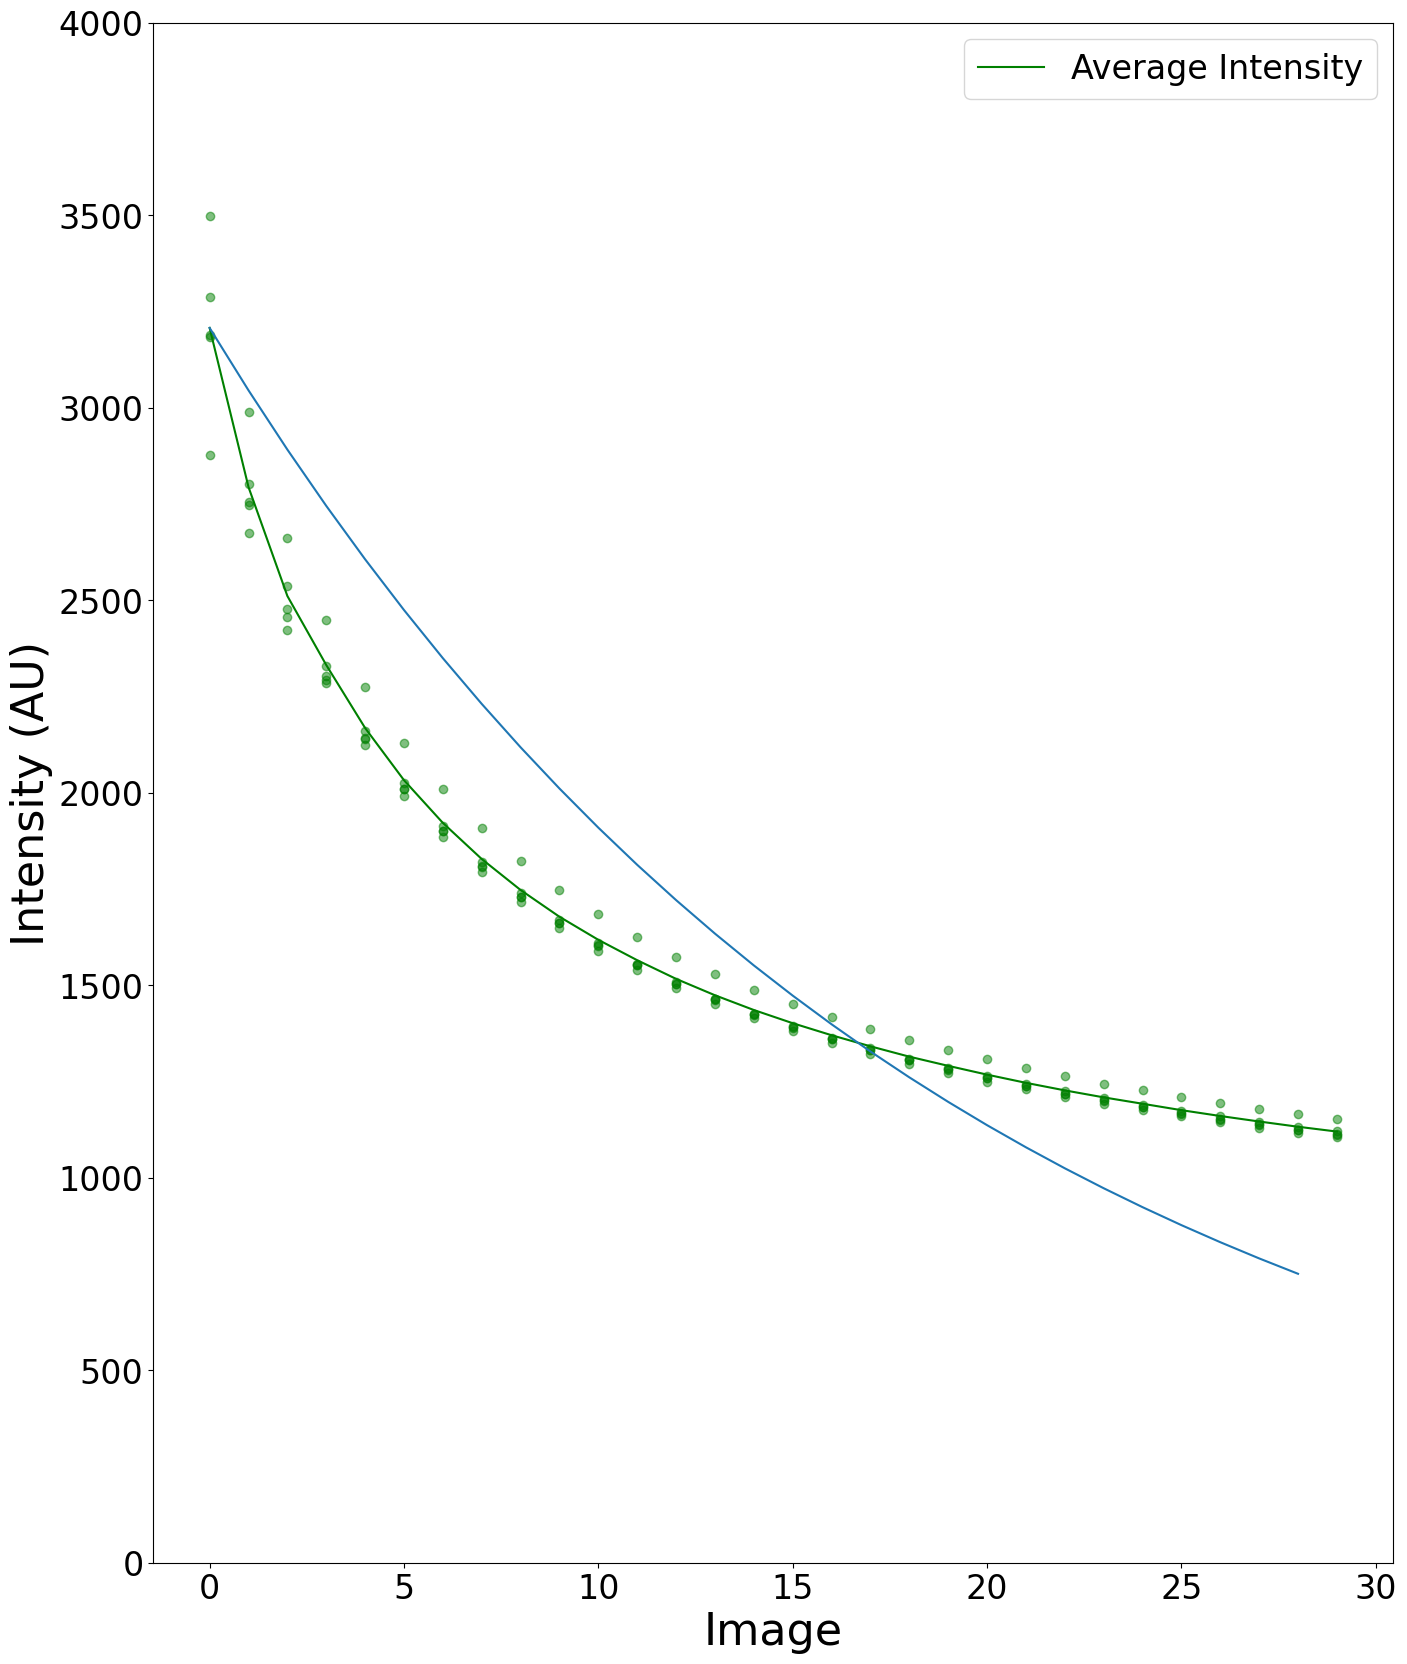

In [118]:
photo_df = full_dataset[full_dataset['ExoIII (nM)'] == 0]

averages = [x for x in photo_df.groupby('Image')['Mean'].mean()]
times = [0.1 * i for (i, x) in enumerate(averages)]

intensity_arr = np.asarray(list(zip(times, averages)))
print(intensity_arr)

I_0 = averages[0]
mean_background = 689.5

def photobleaching(t, tau):
    return I_0 * np.exp(-t * tau) 

popt, pcov = sp.optimize.curve_fit(
    photobleaching, 
    photo_df['Image'].unique(),
    averages
)
print(popt)

curve = I_0 * np.exp(-popt * np.arange(start = 0, stop = 29))
print(curve)
fig, ax = plt.subplots(nrows = 1, ncols = 1, figsize = (16, 20))

ax.scatter(
    photo_df['Image'],
    photo_df['Mean'], 
    color = 'g',
    alpha = 0.5
)
ax.plot(averages, label = 'Average Intensity', color = 'g')
ax.plot(curve)
ax.legend(fontsize = 24)
ax.tick_params(axis = 'both', labelsize = 24)
ax.set_xlabel('Image', fontsize = 32)
ax.set_ylabel('Intensity (AU)', fontsize = 32)
ax.set_ylim((0, 4000))
plt.show()

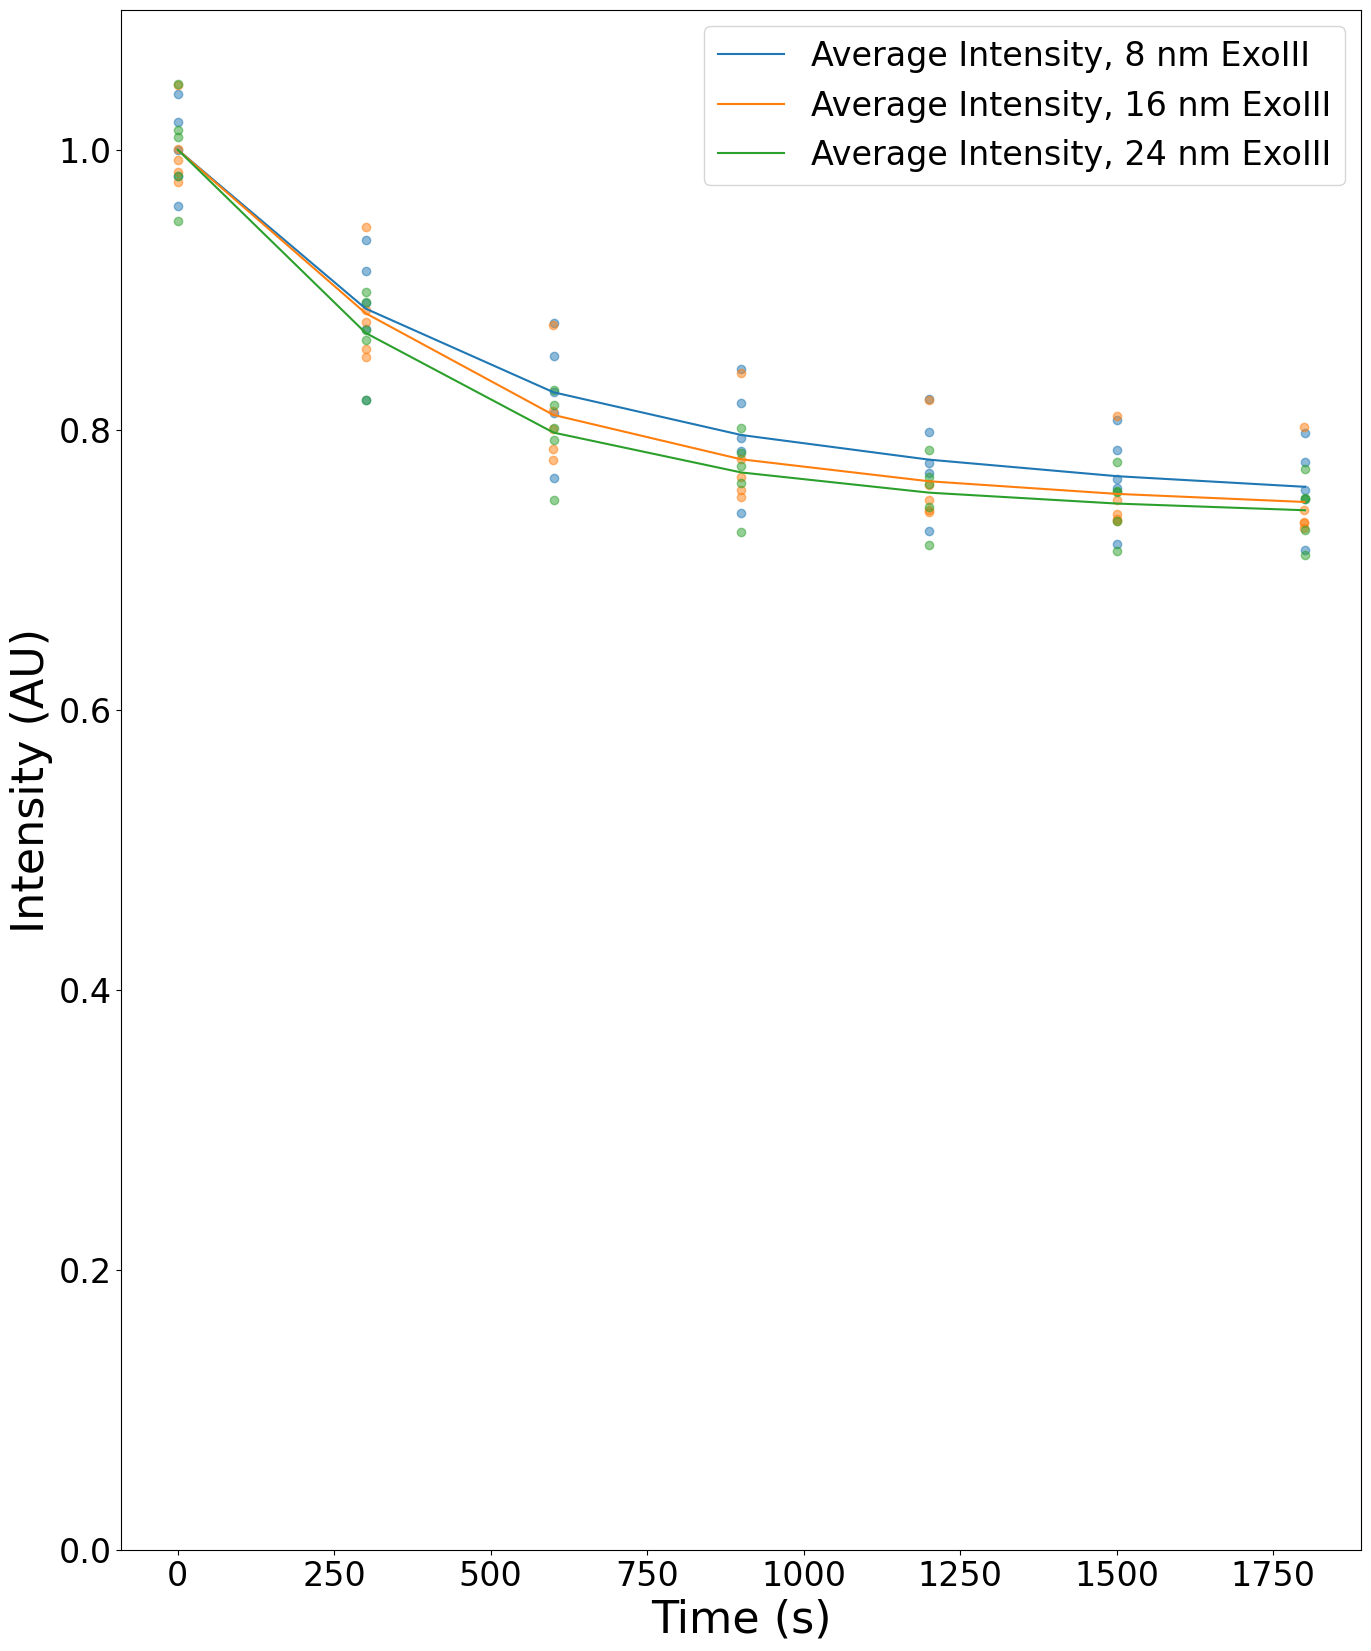

In [124]:
exo_df = full_dataset[full_dataset['ExoIII (nM)'] != 0]
photo_df = full_dataset[full_dataset['ExoIII (nM)'] == 0]

fig, ax = plt.subplots(nrows = 1, ncols = 1, figsize = (16, 20))

# p_averages = [x for x in photo_df.groupby('Image')['Mean'].mean()]
# p_norm_averages = [x / p_averages[0] for x in p_averages]
# photo_df['Norm_Mean'] = photo_df['Mean'] / p_averages[0]
# ax[0].scatter(
#     photo_df['Image'][0:35],
#     photo_df['Norm_Mean'][0:35], 
#     color = 'g',
#     alpha = 0.5
# )
# ax[0].plot(p_averages[0:7], label = 'Average Intensity', color = 'g')

for level, level_df in exo_df.groupby('ExoIII (nM)'):
    averages = [x for x in level_df.groupby('Image')['Mean'].mean()]
    norm_averages = [x / averages[0] for x in averages]
    level_df['Norm_Mean'] = level_df['Mean'] / averages[0]
    ax.scatter(
        level_df['Time (s)'],
        level_df['Norm_Mean'], 
        alpha = 0.5
    )
    ax.plot(level_df['Time (s)'].unique(), norm_averages, label = f'Average Intensity, {level} nm ExoIII')
ax.set_xlabel('Time (s)', fontsize = 32)

ax.legend(fontsize = 24)
ax.tick_params(axis = 'both', labelsize = 24)
ax.set_ylabel('Intensity (AU)', fontsize = 32)
ax.set_ylim((0, 1.1))
plt.show()